# Target engineering

Which value should the model learn? Keep target construction, difference order, and seasonal lag explicit.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp target

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').is_file() and (p / 'timegym').is_dir())
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `target`

### Imports and configuration

In [3]:
# | export target
from __future__ import annotations

from typing import TypeVar
from numpy.typing import NDArray

import numpy as np
import pandas as pd

_Pandas = TypeVar("_Pandas", pd.Series, pd.DataFrame)


### Shared positive integer validation

In [4]:
# | export target
from timegym._internal import positive_int


### multioutput_target

In [5]:
# | export target
def multioutput_target(
    df: pd.DataFrame, horizon: int = 10, dropna: bool = True
) -> pd.DataFrame:
    """Append future labels {column}_t+{h} for h=1..horizon, by source column.

    Retain the original columns without mutation; future columns are supervised
    labels and must never enter the predictor matrix. Offsets count rows, not
    calendar durations. dropna=True removes rows missing any value; False keeps
    the index and incomplete tail labels. Existing generated names raise.
    This constructs labels, not a multioutput forecasting adapter.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    horizon = positive_int(horizon, "horizon")
    df = df.copy()
    for col in df.columns:
        for h in range(1, 1 + horizon):
            name = f"{col}_t+{h}"
            if name in df.columns:
                raise ValueError(f"Future target column already exists: {name}")
            df[name] = df[col].shift(-h)
    return df.dropna() if dropna else df


### onestep_target

In [6]:
# | export target
def onestep_target(df: pd.DataFrame, dropna: bool = True) -> pd.DataFrame:
    """Append each next-row label with multioutput_target's copy/missing contract.

    A recursive forecaster can train on these labels; the helper itself does
    not fit a model or feed predictions back into future inputs.
    """
    return multioutput_target(df, horizon=1, dropna=dropna)


### step_ahead_target

In [7]:
# | export target
def step_ahead_target(
    df: pd.DataFrame, step: int = 5, dropna: bool = True
) -> pd.DataFrame:
    """Append only the label step rows ahead for each original column.

    Keep original columns and never mutate the input. dropna=True removes rows
    missing any original or future value; False retains the incomplete tail.
    Generated names must not collide. This supplies labels for a chosen horizon,
    not a direct forecasting adapter.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    step = positive_int(step, "step")
    df = df.copy()
    for col in df.columns:
        name = f"{col}_t+{step}"
        if name in df.columns:
            raise ValueError(f"Future target column already exists: {name}")
        df[name] = df[col].shift(-step)
    return df.dropna() if dropna else df


### fractional_weights — The first lags binomial coefficients of the operator (1-B)^d.

In [8]:
# | export target
def fractional_weights(d: float, lags: int) -> NDArray[np.float64]:
    """Return (lags, 1) binomial coefficients of (1-B)^d, newest first.

    d may be any finite real order; lags includes the current observation's
    coefficient 1. The array is a finite truncation, not an infinite filter.
    """
    lags = positive_int(lags, "lags")
    if isinstance(d, (bool, np.bool_)):
        raise ValueError("d must be finite and real")
    d = float(d)
    if not np.isfinite(d):
        raise ValueError("d must be finite")
    weights = [1.0]
    for k in range(1, lags):
        weights.append(-weights[-1] * (d - k + 1) / k)
    return np.asarray(weights).reshape(-1, 1)


### fractional_differencing — Apply a finite binomial approximation to (1-B^lag)^order.

In [9]:
# | export target
def fractional_differencing(
    series: _Pandas, order: float, fractional_coefficients: int, *, lag: int = 1
) -> _Pandas:
    """Apply a finite binomial approximation to (1-B^lag)^order.

    Discard only the initial (fractional_coefficients-1)*lag rows that do not
    have a full history. Missing observations inside the series propagate.
    Transform all columns independently, retaining pandas type and labels;
    never mutate the input. Order zero returns a copy without trimming.
    Restore the original target scale in the model before forecast evaluation.
    """
    if not isinstance(series, (pd.Series, pd.DataFrame)):
        raise TypeError("series must be a pandas Series or DataFrame")
    if isinstance(order, (bool, np.bool_)):
        raise ValueError("order must be finite and nonnegative")
    count = positive_int(fractional_coefficients, "fractional_coefficients")
    lag = positive_int(lag, "lag")
    order = float(order)
    if not np.isfinite(order) or order < 0:
        raise ValueError("order must be finite and nonnegative")
    if order == 0:
        return series.copy()
    weights = fractional_weights(order, count)[:, 0]
    result = sum(weights[k] * series.shift(k * lag) for k in range(count))
    return result.iloc[(count - 1) * lag :]


### differencing — Apply repeated lag differences; order is not a lag distance.

In [10]:
# | export target
def differencing(
    series: _Pandas,
    order: float = 1,
    fractional_coefficients: int = 10,
    *,
    lag: int = 1
) -> _Pandas:
    """Apply repeated lag differences; order is not a lag distance.

    order=2 means y[t]-2*y[t-lag]+y[t-2*lag]. For a seasonal first difference
    use order=1, lag=period. Order zero returns a copy unchanged. Noninteger
    orders use the explicitly truncated fractional approximation.
    Return the same pandas type and labels, trimming order*lag warmup rows for
    integer orders. Internal missing values propagate. All columns are treated
    independently without mutation. fractional_coefficients is used only for
    noninteger orders; lag counts rows, not calendar durations.
    """
    if not isinstance(series, (pd.Series, pd.DataFrame)):
        raise TypeError("series must be a pandas Series or DataFrame")
    lag = positive_int(lag, "lag")
    if isinstance(order, (bool, np.bool_)):
        raise ValueError("order must be a finite nonnegative number")
    order = float(order)
    if not np.isfinite(order) or order < 0:
        raise ValueError("order must be a finite nonnegative number")
    if order.is_integer():
        result = series.copy()
        for _ in range(int(order)):
            result = result.diff(periods=lag)
        return result.iloc[int(order) * lag :]
    return fractional_differencing(series, order, fractional_coefficients, lag=lag)


## A first difference is not a seasonal difference

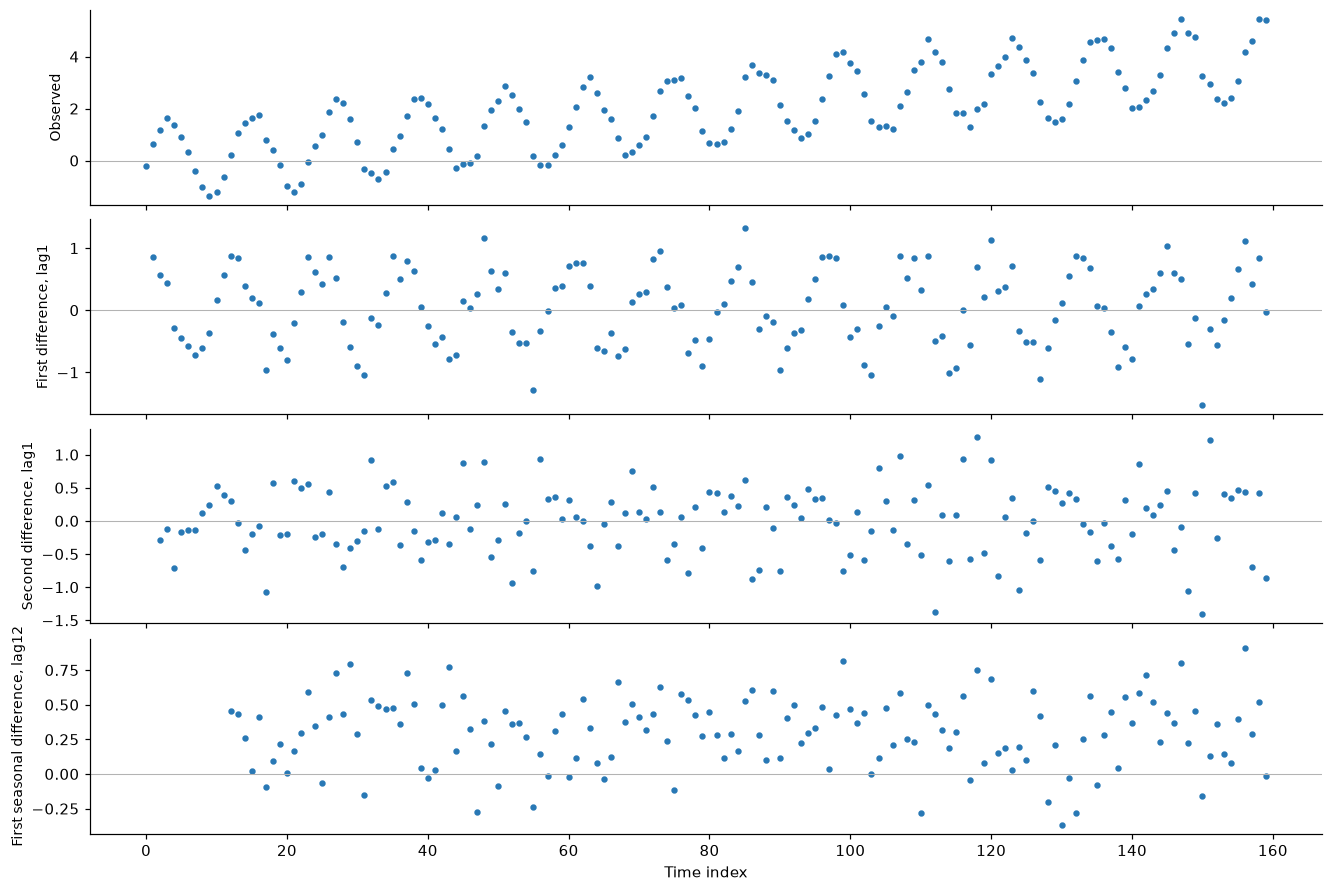

In [11]:
time = np.arange(160)
rng = np.random.default_rng(10)
series = pd.Series(.025 * time + 1.5 * np.sin(2 * np.pi * time / 12) + rng.normal(0, .2, len(time)), name='y')
transforms = {'Observed': series, 'First difference, lag1': differencing(series, order=1),
              'Second difference, lag1': differencing(series, order=2),
              'First seasonal difference, lag12': differencing(series, order=1, lag=12)}
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True, layout='constrained')
for ax, (label, transformed) in zip(axes, transforms.items()):
    ax.scatter(transformed.index, transformed, s=10, color='#2878b5')
    ax.axhline(0, color='.7', lw=.7)
    ax.set_ylabel(label, fontsize=9)
axes[-1].set_xlabel('Time index')
plt.show()
pd.testing.assert_series_equal(differencing(series, order=2), series.diff().diff().iloc[2:])

Order2 applies two successive differences; lag12 compares the same season. Differencing changes the target and its scale. A forecasting model must restore the original scale before evaluation.

## Inspect the supervised targets

In [12]:
small = pd.DataFrame({'y': np.arange(8, dtype=float)})
display(multioutput_target(small, horizon=3))
assert len(multioutput_target(small, horizon=3)) == 5

,y,y_t+1,y_t+2,y_t+3
0,0.0,1.0,2.0,3.0
1,1.0,2.0,3.0,4.0
2,2.0,3.0,4.0,5.0
3,3.0,4.0,5.0,6.0
4,4.0,5.0,6.0,7.0


Each future column is a label, never an input available at the origin. This helper constructs supervised targets; it does not implement direct or multioutput forecasting adapters.

## Change one thing

Try one parameter or implementation change, rerun the relevant example, and inspect the figure or assertion. Save before exporting. The package tests provide broader regression coverage; the experiment here is intentionally small.